Epoch 500/5000 | Total Loss: 5690.153320 | Physics Loss: 23.439915 | Boundary Loss: 5666.713379
Epoch 1000/5000 | Total Loss: 3534.450684 | Physics Loss: 10.284685 | Boundary Loss: 3524.166016
Epoch 1500/5000 | Total Loss: 2112.594482 | Physics Loss: 7.067483 | Boundary Loss: 2105.527100
Epoch 2000/5000 | Total Loss: 1185.224121 | Physics Loss: 6.754207 | Boundary Loss: 1178.469971
Epoch 2500/5000 | Total Loss: 609.222534 | Physics Loss: 5.060257 | Boundary Loss: 604.162292
Epoch 3000/5000 | Total Loss: 279.298767 | Physics Loss: 5.514198 | Boundary Loss: 273.784576
Epoch 3500/5000 | Total Loss: 109.913925 | Physics Loss: 6.425460 | Boundary Loss: 103.488464
Epoch 4000/5000 | Total Loss: 32.090588 | Physics Loss: 0.919558 | Boundary Loss: 31.171030
Epoch 4500/5000 | Total Loss: 7.399203 | Physics Loss: 0.418078 | Boundary Loss: 6.981125
Epoch 5000/5000 | Total Loss: 1.496312 | Physics Loss: 0.408397 | Boundary Loss: 1.087915


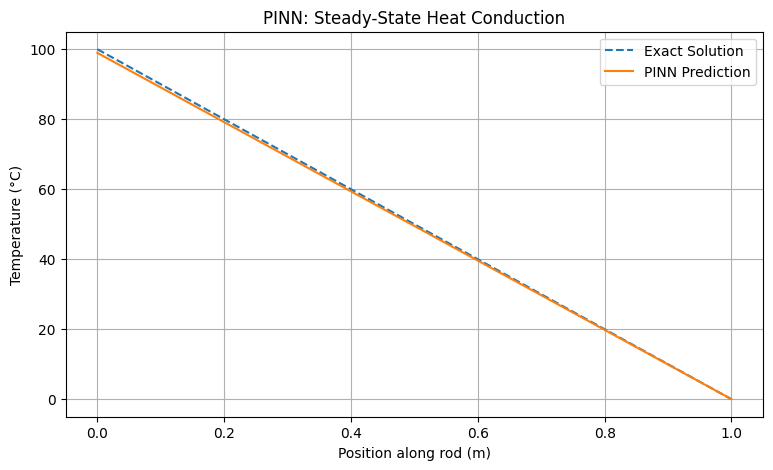

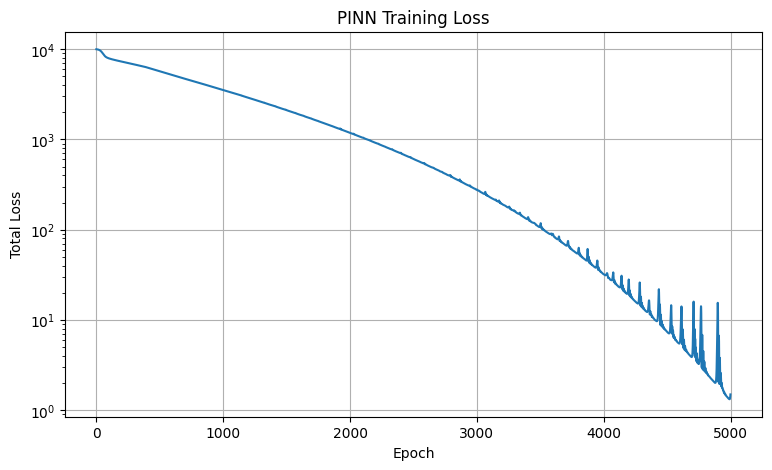


Sample Predictions
-------------------------------
x = 0.00 m | PINN = 98.96 °C | Exact = 100.00 °C
x = 0.25 m | PINN = 74.22 °C | Exact = 75.00 °C
x = 0.50 m | PINN = 49.50 °C | Exact = 50.00 °C
x = 0.75 m | PINN = 24.76 °C | Exact = 25.00 °C
x = 1.00 m | PINN = 0.02 °C | Exact = 0.00 °C


In [12]:
# ============================================================
# PHYSICS-INFORMED NEURAL NETWORK (PINN)
# 1D STEADY-STATE HEAT CONDUCTION
# ============================================================

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Set random seeds
# ------------------------------------------------------------

np.random.seed(42)
tf.random.set_seed(42)

# ------------------------------------------------------------
# 2. Define the physical domain
# ------------------------------------------------------------

L = 1.0  # Rod length in metres

T_left = 100.0   # Temperature at x = 0
T_right = 0.0    # Temperature at x = L

# ------------------------------------------------------------
# 3. Generate collocation points
# ------------------------------------------------------------
# These are points inside the rod where we enforce the physics.
# They are NOT measured temperature data.

n_collocation = 1000

x_physics = tf.random.uniform(
    shape=(n_collocation, 1),
    minval=0.0,
    maxval=L,
    dtype=tf.float32
)

# Boundary points
x_left = tf.constant([[0.0]], dtype=tf.float32)
x_right = tf.constant([[L]], dtype=tf.float32)

# Boundary temperatures
y_left = tf.constant([[T_left]], dtype=tf.float32)
y_right = tf.constant([[T_right]], dtype=tf.float32)

# ------------------------------------------------------------
# 4. Build the neural network
# ------------------------------------------------------------

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1,)),
    tf.keras.layers.Dense(32, activation="tanh"),
    tf.keras.layers.Dense(32, activation="tanh"),
    tf.keras.layers.Dense(32, activation="tanh"),
    tf.keras.layers.Dense(1)
])

# ------------------------------------------------------------
# 5. Define optimizer
# ------------------------------------------------------------

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

# ------------------------------------------------------------
# 6. Training parameters
# ------------------------------------------------------------

epochs = 5000

physics_weight = 1.0
boundary_weight = 1.0

loss_history = []

# ------------------------------------------------------------
# 7. Training loop
# ------------------------------------------------------------

for epoch in range(epochs):

    with tf.GradientTape() as train_tape:

        # ----------------------------------------------------
        # Physics residual: d²T/dx² = 0
        # ----------------------------------------------------

        with tf.GradientTape() as tape2:

            tape2.watch(x_physics)

            with tf.GradientTape() as tape1:

                tape1.watch(x_physics)

                T_pred = model(x_physics, training=True)

            # First derivative dT/dx
            dT_dx = tape1.gradient(T_pred, x_physics)

        # Second derivative d²T/dx²
        d2T_dx2 = tape2.gradient(dT_dx, x_physics)

        # Physics loss
        physics_loss = tf.reduce_mean(
            tf.square(d2T_dx2)
        )

        # ----------------------------------------------------
        # Boundary condition loss
        # ----------------------------------------------------

        T_left_pred = model(x_left, training=True)
        T_right_pred = model(x_right, training=True)

        left_loss = tf.reduce_mean(
            tf.square(T_left_pred - y_left)
        )

        right_loss = tf.reduce_mean(
            tf.square(T_right_pred - y_right)
        )

        boundary_loss = left_loss + right_loss

        # ----------------------------------------------------
        # Total PINN loss
        # ----------------------------------------------------

        total_loss = (
            physics_weight * physics_loss
            + boundary_weight * boundary_loss
        )

    # --------------------------------------------------------
    # Calculate gradients with respect to model parameters
    # --------------------------------------------------------

    gradients = train_tape.gradient(
        total_loss,
        model.trainable_variables
    )

    # Update model parameters
    optimizer.apply_gradients(
        zip(gradients, model.trainable_variables)
    )

    loss_history.append(float(total_loss.numpy()))

    # --------------------------------------------------------
    # Display training progress
    # --------------------------------------------------------

    if (epoch + 1) % 500 == 0:

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Total Loss: {total_loss.numpy():.6f} | "
            f"Physics Loss: {physics_loss.numpy():.6f} | "
            f"Boundary Loss: {boundary_loss.numpy():.6f}"
        )

# ------------------------------------------------------------
# 8. Generate predictions
# ------------------------------------------------------------

x_test = np.linspace(0, L, 100).reshape(-1, 1).astype("float32")

T_pinn = model.predict(
    x_test,
    verbose=0
)

# Exact analytical solution
T_exact = T_left + (
    (T_right - T_left) / L
) * x_test

# ------------------------------------------------------------
# 9. Plot predicted vs exact temperature
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    x_test,
    T_exact,
    label="Exact Solution",
    linestyle="--"
)

plt.plot(
    x_test,
    T_pinn,
    label="PINN Prediction"
)

plt.xlabel("Position along rod (m)")
plt.ylabel("Temperature (°C)")
plt.title("PINN: Steady-State Heat Conduction")

plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# 10. Plot loss
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Total Loss")
plt.title("PINN Training Loss")

plt.yscale("log")
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# 11. Print sample predictions
# ------------------------------------------------------------

sample_positions = np.array(
    [[0.0], [0.25], [0.50], [0.75], [1.0]],
    dtype=np.float32
)

sample_predictions = model.predict(
    sample_positions,
    verbose=0
)

print("\nSample Predictions")
print("-------------------------------")

for x, predicted in zip(
    sample_positions.flatten(),
    sample_predictions.flatten()
):

    exact = T_left + (
        (T_right - T_left) / L
    ) * x

    print(
        f"x = {x:.2f} m | "
        f"PINN = {predicted:.2f} °C | "
        f"Exact = {exact:.2f} °C"
    )

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,209 (8.63 KB)

 Trainable params: 2,209 (8.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 500/5000 | Total Loss: 1274564352.000000 | Physics Loss: 0.023787 | Boundary Loss: 12745643.000000
Epoch 1000/5000 | Total Loss: 1257797248.000000 | Physics Loss: 0.001869 | Boundary Loss: 12577972.000000
Epoch 1500/5000 | Total Loss: 1241504256.000000 | Physics Loss: 0.000383 | Boundary Loss: 12415042.000000
Epoch 2000/5000 | Total Loss: 1225463424.000000 | Physics Loss: 0.000115 | Boundary Loss: 12254634.000000
Epoch 2500/5000 | Total Loss: 1209606400.000000 | Physics Loss: 0.000042 | Boundary Loss: 12096064.000000
Epoch 3000/5000 | Total Loss: 1193901952.000000 | Physics Loss: 0.000017 | Boundary Loss: 11939019.000000
Epoch 3500/5000 | Total Loss: 1178333056.000000 | Physics Loss: 0.000008 | Boundary Loss: 11783330.000000
Epoch 4000/5000 | Total Loss: 1162889216.000000 | Physics Loss: 0.000004 | Boundary Loss: 11628892.000000
Epoch 4500/5000 | Total Loss: 1147564544.000000 | Physics Loss: 0.000002 | Boundary Loss: 11475646.000000
Epoch 5000/5000 | Total Loss: 1132354816.000000

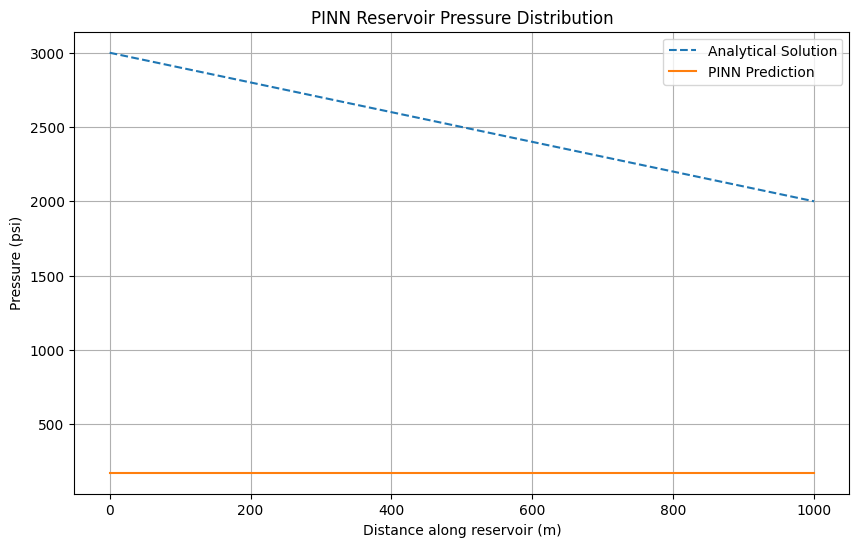

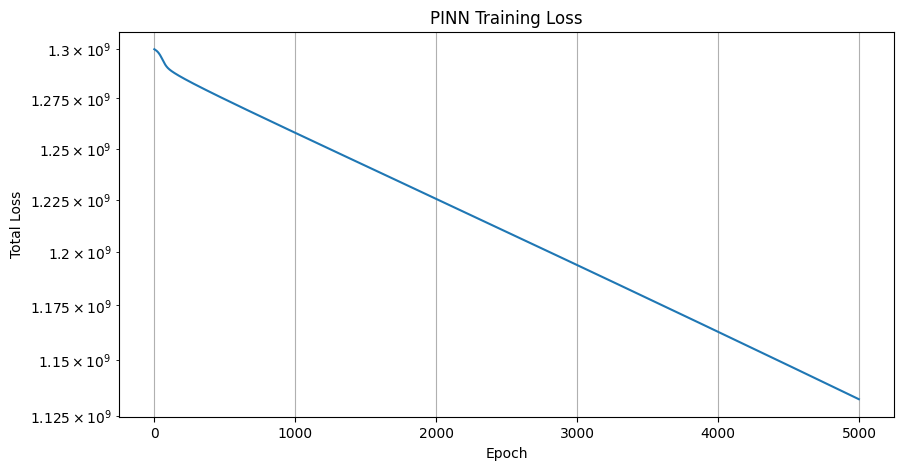

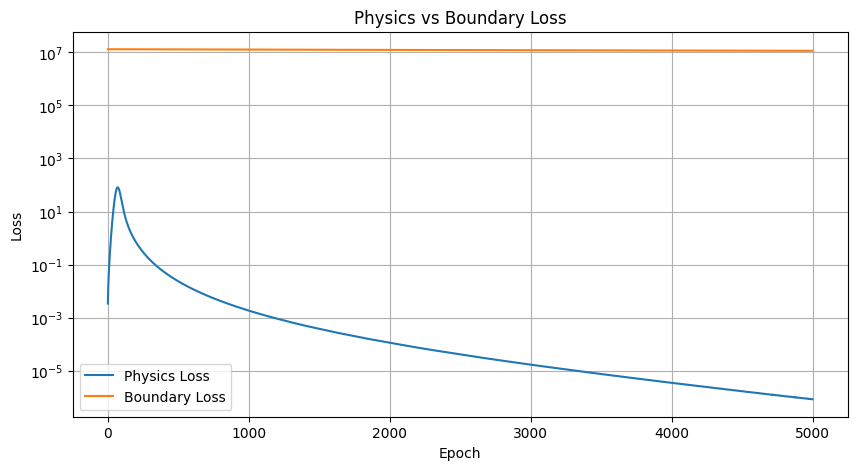


Reservoir Pressure Predictions
Distance:     0.0 m | PINN:   173.71 psi | Analytical:  3000.00 psi
Distance:   250.0 m | PINN:   173.71 psi | Analytical:  2750.00 psi
Distance:   500.0 m | PINN:   173.71 psi | Analytical:  2500.00 psi
Distance:   750.0 m | PINN:   173.71 psi | Analytical:  2250.00 psi
Distance:  1000.0 m | PINN:   173.71 psi | Analytical:  2000.00 psi

Model Evaluation
Mean Squared Error: 5496639.500000
Mean Absolute Error: 2326.289551


In [13]:
# ============================================================
# PETROLEUM ENGINEERING PINN
# 1D STEADY-STATE RESERVOIR PRESSURE DISTRIBUTION
# ============================================================

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

np.random.seed(42)
tf.random.set_seed(42)

# ------------------------------------------------------------
# 2. Reservoir parameters
# ------------------------------------------------------------

reservoir_length = 1000.0  # metres

pressure_left = 3000.0      # psi
pressure_right = 2000.0     # psi

# ------------------------------------------------------------
# 3. Physics equation
# ------------------------------------------------------------
# Simplified steady-state 1D flow with constant properties:
#
# d²P/dx² = 0
#
# We use a normalized coordinate:
# x_normalized = x / reservoir_length
#
# The second derivative with respect to normalized x is also zero.
# ------------------------------------------------------------

n_collocation = 500

x_physics = tf.random.uniform(
    shape=(n_collocation, 1),
    minval=0.0,
    maxval=1.0,
    dtype=tf.float32
)

# Boundary locations (normalized)
x_left = tf.constant([[0.0]], dtype=tf.float32)
x_right = tf.constant([[1.0]], dtype=tf.float32)

# Boundary pressure targets
P_left = tf.constant([[pressure_left]], dtype=tf.float32)
P_right = tf.constant([[pressure_right]], dtype=tf.float32)

# ------------------------------------------------------------
# 4. Build neural network
# ------------------------------------------------------------

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1,)),

    tf.keras.layers.Dense(32, activation="tanh"),
    tf.keras.layers.Dense(32, activation="tanh"),
    tf.keras.layers.Dense(32, activation="tanh"),

    tf.keras.layers.Dense(1)
])

model.summary()

# ------------------------------------------------------------
# 5. Optimizer
# ------------------------------------------------------------

optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001
)

# ------------------------------------------------------------
# 6. Training settings
# ------------------------------------------------------------

epochs = 5000

physics_weight = 1.0
boundary_weight = 100.0

loss_history = []
physics_loss_history = []
boundary_loss_history = []

# ------------------------------------------------------------
# 7. Training loop
# ------------------------------------------------------------

for epoch in range(epochs):

    with tf.GradientTape() as train_tape:

        # ====================================================
        # PHYSICS LOSS
        # ====================================================

        with tf.GradientTape() as tape2:

            tape2.watch(x_physics)

            with tf.GradientTape() as tape1:

                tape1.watch(x_physics)

                P_pred = model(
                    x_physics,
                    training=True
                )

            # First derivative dP/dx
            dP_dx = tape1.gradient(
                P_pred,
                x_physics
            )

        # Second derivative d²P/dx²
        d2P_dx2 = tape2.gradient(
            dP_dx,
            x_physics
        )

        # Physics residual
        physics_loss = tf.reduce_mean(
            tf.square(d2P_dx2)
        )

        # ====================================================
        # BOUNDARY CONDITION LOSS
        # ====================================================

        P_pred_left = model(
            x_left,
            training=True
        )

        P_pred_right = model(
            x_right,
            training=True
        )

        left_loss = tf.reduce_mean(
            tf.square(P_pred_left - P_left)
        )

        right_loss = tf.reduce_mean(
            tf.square(P_pred_right - P_right)
        )

        boundary_loss = left_loss + right_loss

        # ====================================================
        # TOTAL LOSS
        # ====================================================

        total_loss = (
            physics_weight * physics_loss
            + boundary_weight * boundary_loss
        )

    # ========================================================
    # GRADIENTS AND WEIGHT UPDATE
    # ========================================================

    gradients = train_tape.gradient(
        total_loss,
        model.trainable_variables
    )

    optimizer.apply_gradients(
        zip(gradients, model.trainable_variables)
    )

    # Record losses
    loss_history.append(float(total_loss.numpy()))
    physics_loss_history.append(float(physics_loss.numpy()))
    boundary_loss_history.append(float(boundary_loss.numpy()))

    # ========================================================
    # TRAINING PROGRESS
    # ========================================================

    if (epoch + 1) % 500 == 0:

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Total Loss: {total_loss.numpy():.6f} | "
            f"Physics Loss: {physics_loss.numpy():.6f} | "
            f"Boundary Loss: {boundary_loss.numpy():.6f}"
        )

# ------------------------------------------------------------
# 8. Generate predictions
# ------------------------------------------------------------

x_normalized_test = np.linspace(
    0.0,
    1.0,
    100
).reshape(-1, 1).astype(np.float32)

# Convert normalized distance back to metres
x_meters = x_normalized_test * reservoir_length

# PINN predictions
P_pinn = model.predict(
    x_normalized_test,
    verbose=0
)

# Analytical solution
P_exact = (
    pressure_left
    + (pressure_right - pressure_left)
    * x_normalized_test
)

# ------------------------------------------------------------
# 9. Plot pressure distribution
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    x_meters,
    P_exact,
    linestyle="--",
    label="Analytical Solution"
)

plt.plot(
    x_meters,
    P_pinn,
    label="PINN Prediction"
)

plt.xlabel("Distance along reservoir (m)")
plt.ylabel("Pressure (psi)")
plt.title("PINN Reservoir Pressure Distribution")

plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# 10. Plot total loss
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Total Loss")
plt.title("PINN Training Loss")
plt.yscale("log")
plt.grid(True)

plt.show()

# ------------------------------------------------------------
# 11. Plot individual losses
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    physics_loss_history,
    label="Physics Loss"
)

plt.plot(
    boundary_loss_history,
    label="Boundary Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Physics vs Boundary Loss")

plt.yscale("log")
plt.legend()
plt.grid(True)

plt.show()

# ------------------------------------------------------------
# 12. Display sample pressure predictions
# ------------------------------------------------------------

sample_distances = np.array(
    [[0.0], [0.25], [0.50], [0.75], [1.0]],
    dtype=np.float32
)

sample_predictions = model.predict(
    sample_distances,
    verbose=0
)

print("\nReservoir Pressure Predictions")
print("=" * 55)

for normalized_x, predicted_pressure in zip(
    sample_distances.flatten(),
    sample_predictions.flatten()
):

    distance = normalized_x * reservoir_length

    exact_pressure = (
        pressure_left
        + (pressure_right - pressure_left)
        * normalized_x
    )

    print(
        f"Distance: {distance:7.1f} m | "
        f"PINN: {predicted_pressure:8.2f} psi | "
        f"Analytical: {exact_pressure:8.2f} psi"
    )

# ------------------------------------------------------------
# 13. Calculate prediction error
# ------------------------------------------------------------

mse = np.mean(
    (P_pinn - P_exact) ** 2
)

mae = np.mean(
    np.abs(P_pinn - P_exact)
)

print("\nModel Evaluation")
print("=" * 30)
print(f"Mean Squared Error: {mse:.6f}")
print(f"Mean Absolute Error: {mae:.6f}")